# 03 · Догрузка 2ГИС для непокрытых кандидатов

Основной сбор 2ГИС (`03_2gis_data_safe.ipynb`) искал кофейни в радиусе 1 км вокруг 413 центров сетки 1 км. 18 кандидатных точек, у которых есть признаки окружения, остались дальше 1 км от всех центров. Здесь мы подбираем для них дополнительные центры, собираем заведения тем же поиском и сохраняем результат отдельно, чтобы потом объединить его с основной выгрузкой по ID 2ГИС.

**Входы**
- `data/raw/2gis_coverage_gap_candidates.csv` — 18 непокрытых точек из основного сбора (`candidate_row`, `longitude`, `latitude`, признаки 02).
- `data/processed/candidate_locations.gpkg` и `data/processed/almaty_boundary.gpkg` из `02_candidate_locations.ipynb`.
- Ключ 2ГИС — переменная окружения `DGIS_API_KEY` или строка `DGIS_API_KEY=...` в файле `.env` в корне проекта. Он нужен только для сбора.

**Выходы** — папка `data/processed/2gis_gap/`
- `gap_centers.csv` — центры поиска и `candidate_id`, которые они покрывают.
- `gap_progress.sqlite3` — прогресс сборщика: страницы, организации, HTTP-попытки.
- `gap_organizations.csv` — найденные заведения: `id` 2ГИС (текст), название, координаты, рейтинг и центры, которые их нашли.
- `gap_centers_status.csv` и `gap_summary.json` — статус каждого центра и общее число HTTP-попыток.

С настройками по умолчанию ноутбук не обращается к 2ГИС: он подбирает центры, прогоняет офлайн-тесты и рисует карту.

In [1]:
from contextlib import closing, contextmanager
from dataclasses import dataclass
from datetime import timezone
from email.utils import parsedate_to_datetime
import itertools
import json
import math
import os
from pathlib import Path
import random
import sqlite3
import time

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
import shapely

try:  # блокировка файла прогресса: fcntl на macOS/Linux, msvcrt на Windows
    import fcntl
except ImportError:
    fcntl = None
    import msvcrt

PROJECT_ROOT = (Path("..") if Path.cwd().name == "notebooks" else Path(".")).resolve()
GAP_CSV = PROJECT_ROOT / "data" / "raw" / "2gis_coverage_gap_candidates.csv"
CANDIDATES_PATH = PROJECT_ROOT / "data" / "processed" / "candidate_locations.gpkg"
BOUNDARY_PATH = PROJECT_ROOT / "data" / "processed" / "almaty_boundary.gpkg"
OUT_DIR = PROJECT_ROOT / "data" / "processed" / "2gis_gap"
CENTERS_CSV = OUT_DIR / "gap_centers.csv"
CHECKPOINT = OUT_DIR / "gap_progress.sqlite3"
ORGS_CSV_NAME = "gap_organizations.csv"
STATUS_CSV_NAME = "gap_centers_status.csv"
SUMMARY_JSON_NAME = "gap_summary.json"

CRS_METRIC = "EPSG:32643"
SEARCH_RADIUS_M = 1000  # как в основном сборе
FULL_COVER_M = 500      # кандидат не дальше 500 м от центра → его круг 500 м целиком внутри поиска радиусом 1000 м

## Непокрытые кандидаты

`candidate_id` берём из сетки 02 по координатам, а не из `candidate_row`. В CSV `candidate_row` на 1 больше `candidate_id` у всех точек (нумерация с 1). Если объединять по `candidate_row`, каждая точка получит признаки соседней.

In [2]:
for path in (GAP_CSV, CANDIDATES_PATH, BOUNDARY_PATH):
    if not path.is_file():
        raise FileNotFoundError(
            f"Нет файла {path.relative_to(PROJECT_ROOT)}. CSV непокрытых точек положите в data/raw, "
            "сетку и границу создаёт 02_candidate_locations.ipynb."
        )

grid = gpd.read_file(CANDIDATES_PATH)
if "candidate_id" not in grid.columns:
    raise ValueError("В candidate_locations.gpkg нет столбца candidate_id. "
                     "Пересоберите сетку через 02_candidate_locations.ipynb.")
grid = grid[["candidate_id", "geometry"]].to_crs(CRS_METRIC)
city = gpd.read_file(BOUNDARY_PATH).to_crs(CRS_METRIC)

gap = pd.read_csv(GAP_CSV)
gap = gpd.GeoDataFrame(
    gap, geometry=gpd.points_from_xy(gap["longitude"], gap["latitude"]), crs="EPSG:4326"
).to_crs(CRS_METRIC)
matched = gpd.sjoin_nearest(gap, grid, how="left", distance_col="dist_to_grid_m")
assert len(matched) == len(gap), "у точки CSV несколько равноудалённых кандидатов"
assert matched["dist_to_grid_m"].max() < 0.01, "точка CSV не совпадает ни с одним кандидатом сетки 02"
gap["candidate_id"] = matched["candidate_id"].to_numpy()
assert gap["candidate_id"].is_unique
assert (gap["nearest_search_center_m"] > SEARCH_RADIUS_M).all(), "в CSV есть точка, уже покрытая основным сбором"

print(f"Непокрытых кандидатов: {len(gap)}; совпадение с сеткой 02: до {matched['dist_to_grid_m'].max():.4f} м")
print("candidate_row − candidate_id:", (gap["candidate_row"] - gap["candidate_id"]).value_counts().to_dict())
gap[["candidate_row", "candidate_id", "longitude", "latitude", "nearest_search_center_m", "cafes_500m", "bus_stops_500m"]]

Непокрытых кандидатов: 18; совпадение с сеткой 02: до 0.0006 м
candidate_row − candidate_id: {1: 18}


,candidate_row,candidate_id,longitude,latitude,nearest_search_center_m,cafes_500m,bus_stops_500m
0,27,26,76.777097,43.248084,1118.03,0,0
1,71,70,76.789937,43.265892,1118.03,0,1
2,82,81,76.791786,43.328894,1118.03,0,0
3,115,114,76.797552,43.315297,1118.03,0,3
4,446,445,76.841372,43.337110,1118.03,0,0
5,741,740,76.878983,43.156410,1581.14,0,0
6,742,741,76.879121,43.160910,1118.03,0,0
7,1246,1245,76.932600,43.101490,1118.03,1,0
8,1806,1805,76.985359,43.402232,1118.03,0,2
9,2162,2161,77.011306,43.253209,1118.03,0,0


## Дополнительные центры поиска

Центр ставим так, чтобы каждый кандидат был не дальше 500 м от него. Тогда круг 500 м вокруг кандидата целиком входит в поиск радиусом 1 км, и признаки «в радиусе 500 м» по 2ГИС у этих точек будут полными. Если несколько кандидатов помещаются в круг радиусом 500 м, покрываем их одним центром в середине этого круга.

Варианты центров — минимальные охватывающие окружности для одного, двух или трёх кандидатов радиусом не больше 500 м. Из них жадно выбираем вариант, который покрывает больше всего ещё не покрытых кандидатов, а при равенстве — тот, где самый дальний кандидат ближе к центру.

Порядок обхода (`order`) такой: сначала центры, у кандидатов которых в 02 уже есть кафе, потом центры, покрывающие несколько кандидатов. Пробная партия — первые `CENTER_LIMIT` центров этого порядка.

In [3]:
xy = np.c_[gap.geometry.x, gap.geometry.y]
n = len(xy)
pair_dist = np.hypot(*(xy[:, None, :] - xy[None, :, :]).transpose(2, 0, 1))

options = []
for k in (1, 2, 3):
    for combo in itertools.combinations(range(n), k):
        if k > 1 and pair_dist[np.ix_(combo, combo)].max() > 2 * FULL_COVER_M:
            continue
        pts = shapely.multipoints(xy[list(combo)])
        if shapely.minimum_bounding_radius(pts) > FULL_COVER_M:
            continue
        centre = shapely.get_coordinates(shapely.centroid(shapely.minimum_bounding_circle(pts)))[0].round(2)
        covered = frozenset(np.flatnonzero(np.hypot(*(xy - centre).T) <= FULL_COVER_M + 1e-6).tolist())
        options.append((centre, covered))

uncovered, chosen = set(range(n)), []
while uncovered:
    def score(option):
        new = sorted(option[1] & uncovered)
        worst = np.hypot(*(xy[new] - option[0]).T).max() if new else np.inf
        return (len(new), -worst, -min(option[1]))
    centre, covered = max(options, key=score)
    new = sorted(covered & uncovered)
    chosen.append((centre, new))
    uncovered -= set(new)

centers = gpd.GeoDataFrame(
    {
        "center_id": [f"gap_{i:02d}" for i in range(1, len(chosen) + 1)],
        "candidate_ids": [";".join(str(gap["candidate_id"].iloc[k]) for k in new) for _, new in chosen],
        "n_candidates": [len(new) for _, new in chosen],
        "cafes_500m_02": [int(gap["cafes_500m"].iloc[new].max()) for _, new in chosen],
    },
    geometry=gpd.points_from_xy([c[0] for c, _ in chosen], [c[1] for c, _ in chosen]),
    crs=CRS_METRIC,
)
# point уходит в 2ГИС как «долгота,широта» с 6 знаками (~0,1 м)
lonlat = centers.to_crs("EPSG:4326").geometry
centers["point"] = [f"{p.x:.6f},{p.y:.6f}" for p in lonlat]
sent = gpd.GeoSeries(
    gpd.points_from_xy(*np.array([s.split(",") for s in centers["point"]], dtype=float).T), crs="EPSG:4326"
).to_crs(CRS_METRIC)
centers["x"], centers["y"] = sent.x.round(2).to_numpy(), sent.y.round(2).to_numpy()
centers["max_dist_to_candidate_m"] = [
    np.hypot(*(xy[new] - (cx, cy)).T).max().round(1) for (_, new), cx, cy in zip(chosen, centers["x"], centers["y"])
]
centers = centers.sort_values(["cafes_500m_02", "n_candidates", "center_id"], ascending=[False, False, True])
centers.insert(1, "order", np.arange(1, len(centers) + 1))
centers = centers.sort_values("center_id").reset_index(drop=True)

covered_ids = sorted(int(c) for ids in centers["candidate_ids"] for c in ids.split(";"))
assert covered_ids == sorted(gap["candidate_id"]), "каждый кандидат должен попасть ровно в один центр"
assert (centers["max_dist_to_candidate_m"] <= FULL_COVER_M + 0.5).all()
assert centers["point"].is_unique

OUT_DIR.mkdir(parents=True, exist_ok=True)
centers.drop(columns="geometry").to_csv(CENTERS_CSV, index=False, lineterminator="\n")
print(f"Центров: {len(centers)} на {n} кандидатов; сохранено в {CENTERS_CSV.relative_to(PROJECT_ROOT)}")
centers.drop(columns="geometry").sort_values("order")

Центров: 14 на 18 кандидатов; сохранено в data\processed\2gis_gap\gap_centers.csv


,center_id,order,candidate_ids,n_candidates,cafes_500m_02,point,x,y,max_dist_to_candidate_m
13,gap_14,1,2535,1,2,"77.051528,43.166952",666765.56,4781397.78,0.0
8,gap_09,2,1245,1,1,"76.932600,43.101490",657265.56,4773897.84,0.0
0,gap_01,3,2654;2684,2,0,"77.073043,43.166564",668515.60,4781397.78,250.0
1,gap_02,4,2677;2678,2,0,"77.074214,43.110265",668765.62,4775147.80,250.0
2,gap_03,5,740;741,2,0,"76.879052,43.158660",652765.57,4780147.77,250.0
3,gap_04,6,2388;2441,2,0,"77.036086,43.164977",665515.60,4781147.80,353.6
4,gap_05,7,2657,1,0,"77.070426,43.180118",668265.62,4782897.77,0.1
5,gap_06,8,114,1,0,"76.797552,43.315297",645765.56,4797397.84,0.0
6,gap_07,9,2161,1,0,"77.011306,43.253208",663265.55,4790897.75,0.1
7,gap_08,10,26,1,0,"76.777097,43.248084",644265.59,4789897.85,0.0


## Сборщик

Код сборщика взят из `03_2gis_data_safe.ipynb`, логика запросов, повторов, бюджета и пагинации та же. Отличается только блокировка файла прогресса. В исходнике она работает через `fcntl`, а этого модуля нет на Windows, поэтому здесь на Windows используется `msvcrt`. Параметры поиска те же, что в основном сборе, иначе выдачи будут несравнимы.

In [4]:
PLACES_URL = "https://catalog.api.2gis.com/3.0/items"


class CollectionStopped(RuntimeError):
    """Остановка, после которой сохранённый прогресс можно использовать снова."""


@dataclass(frozen=True)
class Search:
    query: str = "кофейня"
    radius_m: int = 1000
    page_size: int = 10
    max_pages: int = 5

    def __post_init__(self):
        if (not isinstance(self.query, str) or not self.query.strip()
                or type(self.radius_m) is not int or not 1 <= self.radius_m <= 50_000):
            raise ValueError("Проверьте текст поиска и радиус.")
        if (type(self.page_size) is not int or not 1 <= self.page_size <= 50
                or type(self.max_pages) is not int or not 1 <= self.max_pages <= 1_000_000):
            raise ValueError("Проверьте размер страницы и предел страниц.")

    def params(self):
        return {
            "q": self.query, "type": "branch", "radius": self.radius_m,
            "page_size": self.page_size, "fields": "items.point,items.reviews",
        }


def retry_after_seconds(value, now):
    """Retry-After может содержать число секунд или дату HTTP."""
    if not value:
        return 0
    value = value.strip()
    try:
        if value.isascii() and value.isdecimal():
            return int(value) if len(value) <= 12 else math.inf
        retry_at = parsedate_to_datetime(value)
        if retry_at.tzinfo is None:
            retry_at = retry_at.replace(tzinfo=timezone.utc)
        return max(0, retry_at.timestamp() - now)
    except (TypeError, ValueError, OverflowError):
        return 0


class RequestBudget:
    """Лимит всех попыток и самое раннее время следующего запроса."""

    def __init__(self, db, limit, interval, *, now=time.time, sleep=time.sleep):
        self.db = db
        self.limit = limit
        self.interval = interval
        self.now = now
        self.sleep = sleep

    def defer(self, deadline):
        with self.db:
            self.db.execute("UPDATE run SET next_at = max(next_at, ?)", (deadline,))

    def reserve(self):
        attempts, next_at = self.db.execute("SELECT attempts, next_at FROM run").fetchone()
        if attempts >= self.limit:
            raise CollectionStopped("Достигнут суммарный лимит HTTP-попыток.")
        delay = next_at - self.now()
        if delay > 60:
            raise CollectionStopped("Пауза после временной ошибки ещё действует.")
        while delay > 0:
            self.sleep(delay)
            delay = next_at - self.now()
        # Списываем попытку до отправки. При прерывании счётчик консервативен.
        with self.db:
            self.db.execute(
                "UPDATE run SET attempts = attempts + 1, next_at = ?",
                (self.now() + self.interval,),
            )


def get_with_retry(get, params, budget, max_attempts=3):
    """Проверяет HTTP и meta.code, возвращает JSON успешного ответа."""
    for attempt in range(max_attempts):
        budget.reserve()
        retry_after = None
        try:
            response = get(PLACES_URL, params=params, timeout=(5, 15), allow_redirects=False)
        except (requests.exceptions.SSLError, requests.exceptions.ProxyError):
            raise CollectionStopped("Ошибка TLS или прокси.") from None
        except (requests.exceptions.Timeout, requests.exceptions.ConnectionError):
            reason = "временный сетевой сбой"
        except requests.exceptions.RequestException:
            raise CollectionStopped("Ошибка при отправке HTTP-запроса.") from None
        else:
            status = response.status_code
            retry_after = response.headers.get("Retry-After")
            if status == 200:
                try:
                    data = response.json()
                except ValueError:
                    raise CollectionStopped("Ответ 2ГИС не является JSON.") from None
                meta = data.get("meta") if isinstance(data, dict) else None
                code = meta.get("code") if isinstance(meta, dict) else None
                if type(code) is not int:
                    raise CollectionStopped("В ответе 2ГИС отсутствует числовой meta.code.")
                if code == 200:
                    return data
                error = meta.get("error")
                if code == 404 and isinstance(error, dict) and error.get("type") == "itemNotFound":
                    return {"result": {"items": [], "total": 0}}
                if code not in (408, 429) and not 500 <= code <= 599:
                    raise CollectionStopped(f"2ГИС вернул meta.code {code}.")
                reason = f"meta.code {code}"
            else:
                if status not in (408, 429) and not 500 <= status <= 599:
                    raise CollectionStopped(f"2ГИС вернул HTTP {status}.")
                reason = f"HTTP {status}"
        now = budget.now()
        server_delay = retry_after_seconds(retry_after, now)
        delay = max(server_delay, 2 ** attempt + random.uniform(0, 0.5))
        budget.defer(now + delay)
        if attempt + 1 == max_attempts or delay > 60:
            raise CollectionStopped(f"Пауза в сборе 2ГИС ({reason}).")


def page_items(data, page_size):
    result = data.get("result")
    total = result.get("total") if isinstance(result, dict) else None
    if type(total) is not int or total < 0:
        raise CollectionStopped("В ответе 2ГИС отсутствует корректный result.total.")
    items = result.get("items", [] if total == 0 else None)
    if not isinstance(items, list) or len(items) > min(total, page_size):
        raise CollectionStopped("Некорректный список result.items.")
    for item in items:
        item_id = item.get("id") if isinstance(item, dict) else None
        if not isinstance(item_id, str) or not item_id.strip():
            raise CollectionStopped("В result.items есть объект без строкового ID.")
    return total, items


SCHEMA = """
CREATE TABLE IF NOT EXISTS run (
    id INTEGER PRIMARY KEY CHECK (id = 1),
    plan TEXT NOT NULL,
    attempts INTEGER NOT NULL DEFAULT 0,
    next_at REAL NOT NULL DEFAULT 0
);
CREATE TABLE IF NOT EXISTS centers (
    point TEXT PRIMARY KEY,
    next_page INTEGER NOT NULL DEFAULT 1,
    expected_total INTEGER,
    status TEXT NOT NULL DEFAULT 'pending'
);
CREATE TABLE IF NOT EXISTS center_items (
    point TEXT NOT NULL,
    organization_id TEXT NOT NULL,
    PRIMARY KEY (point, organization_id)
);
CREATE TABLE IF NOT EXISTS organizations (
    id TEXT PRIMARY KEY,
    name TEXT,
    lon REAL,
    lat REAL,
    general_rating REAL,
    general_review_count INTEGER
);
"""


@contextmanager
def file_lock(path):
    """Один сборщик на файл прогресса. Блокировка снимается при выходе или завершении процесса."""
    with Path(path).open("a+") as lock:
        try:
            if fcntl is not None:
                fcntl.flock(lock, fcntl.LOCK_EX | fcntl.LOCK_NB)
            else:
                lock.seek(0)
                msvcrt.locking(lock.fileno(), msvcrt.LK_NBLCK, 1)
        except OSError:
            raise CollectionStopped("Этот файл прогресса уже используется.") from None
        try:
            yield
        finally:
            if fcntl is None:
                lock.seek(0)
                msvcrt.locking(lock.fileno(), msvcrt.LK_UNLCK, 1)


@contextmanager
def open_checkpoint(path):
    path = Path(path).resolve()
    path.parent.mkdir(parents=True, exist_ok=True)
    with file_lock(path.with_suffix(path.suffix + ".lock")):
        with closing(sqlite3.connect(path)) as db:
            db.executescript(SCHEMA)
            yield db


def prepare_checkpoint(db, points, search):
    plan = json.dumps(
        {"version": 1, "url": PLACES_URL, "params": search.params(),
         "max_pages": search.max_pages, "points": points},
        ensure_ascii=False, sort_keys=True,
    )
    existing = db.execute("SELECT plan FROM run").fetchone()
    if existing and existing[0] != plan:
        raise CollectionStopped("План поиска изменился. Выберите новый файл прогресса.")
    if not existing:
        with db:
            db.execute("INSERT INTO run (id, plan) VALUES (1, ?)", (plan,))
            db.executemany("INSERT INTO centers (point) VALUES (?)", [(p,) for p in points])


def organization_row(item):
    point = item.get("point")
    lon, lat = (point.get("lon"), point.get("lat")) if isinstance(point, dict) else (None, None)
    if not (type(lon) in (int, float) and -180 <= lon <= 180 and type(lat) in (int, float) and -90 <= lat <= 90):
        lon, lat = None, None
    reviews = item.get("reviews")
    reviews = reviews if isinstance(reviews, dict) else {}
    rating = reviews.get("general_rating")
    count = reviews.get("general_review_count")
    return (
        item["id"], item.get("name") if isinstance(item.get("name"), str) else None,
        lon, lat,
        rating if type(rating) in (int, float) and 0 <= rating <= 1e6 else None,
        count if type(count) is int and 0 <= count < 2**63 else None,
    )


def fetch_coffee_shops(db, point, search, key, get, budget):
    page, expected_total, status = db.execute(
        "SELECT next_page, expected_total, status FROM centers WHERE point = ?", (point,)
    ).fetchone()
    while status == "pending":
        params = dict(search.params(), key=key, point=point, page=page)
        total, items = page_items(get_with_retry(get, params, budget), search.page_size)
        # Если выдача меняется во время сбора, учитываем наибольший заявленный total.
        expected_total = max(total, expected_total or 0)
        # Записи страницы и курсор фиксируются одной транзакцией.
        with db:
            db.executemany(
                """INSERT INTO organizations VALUES (?, ?, ?, ?, ?, ?)
                   ON CONFLICT(id) DO UPDATE SET
                       name = coalesce(excluded.name, organizations.name),
                       lon = coalesce(excluded.lon, organizations.lon),
                       lat = coalesce(excluded.lat, organizations.lat),
                       general_rating = coalesce(excluded.general_rating, organizations.general_rating),
                       general_review_count = coalesce(excluded.general_review_count,
                                                       organizations.general_review_count)""",
                map(organization_row, items),
            )
            db.executemany("INSERT OR IGNORE INTO center_items VALUES (?, ?)", ((point, item["id"]) for item in items))
            seen = db.execute("SELECT count(*) FROM center_items WHERE point = ?", (point,)).fetchone()[0]
            if seen >= expected_total:
                status = "complete"
            elif not items or page * search.page_size >= expected_total:
                status = "short"
            elif page >= search.max_pages:
                status = "capped"
            db.execute(
                "UPDATE centers SET next_page = ?, expected_total = ?, status = ? WHERE point = ?",
                (page + 1, expected_total, status, point),
            )
        page += 1


def checkpoint_summary(db):
    statuses = {status: 0 for status in ("pending", "complete", "capped", "short")}
    statuses.update(db.execute("SELECT status, count(*) FROM centers GROUP BY status"))
    attempts = db.execute("SELECT attempts FROM run").fetchone()[0]
    total, missing = db.execute("SELECT count(*), count(*) - count(lon) FROM organizations").fetchone()
    return {"attempts": attempts, "centers": statuses, "organizations": total, "without_coordinates": missing}


def collect(points, search, checkpoint, *, key, max_requests_total, center_limit, get,
            interval=1.0, now=time.time, sleep=time.sleep):
    points = tuple(dict.fromkeys(points))
    if not key or not points:
        raise ValueError("Для сбора нужны ключ и центры поиска.")
    if type(max_requests_total) is not int or max_requests_total < 1:
        raise ValueError("Укажите положительный суммарный лимит HTTP-попыток.")
    if type(center_limit) is not int or not 1 <= center_limit <= len(points):
        raise ValueError("Укажите число центров от 1 до размера сетки.")
    if not math.isfinite(interval) or not 1 <= interval <= 60:
        raise ValueError("Пауза между запросами должна составлять от 1 до 60 секунд.")
    with open_checkpoint(checkpoint) as db:
        prepare_checkpoint(db, points, search)
        budget = RequestBudget(db, max_requests_total, interval, now=now, sleep=sleep)
        stop_reason = None
        for index, point in enumerate(points[:center_limit], start=1):
            try:
                fetch_coffee_shops(db, point, search, key, get, budget)
            except CollectionStopped as error:
                stop_reason = f"Центр {index}/{len(points)}. {error}"
                break
        return checkpoint_summary(db) | {"stop_reason": stop_reason}

## Выгрузка

`gap_organizations.csv` — одна строка на заведение 2ГИС с координатами, по возрастанию `id`.
- `id` хранится текстом. Это 17-значные числа: Excel портит их, а в pandas при пропусках они становятся float. Тогда объединение с основной выгрузкой по ID молча не сработает, поэтому читайте файл с `dtype={"id": str}`.
- `found_by` перечисляет центры, которые нашли заведение.
- Заведения без координат в CSV не попадают, их число есть в сводке.

`gap_centers_status.csv` — по каждому центру: статус, полученные страницы, заявленный 2ГИС `total` и число найденных заведений. `gap_summary.json` — общее число HTTP-попыток с повторами, статусы центров и параметры поиска.

In [5]:
def export_gap_results(checkpoint, centers, out_dir):
    checkpoint, out_dir = Path(checkpoint), Path(out_dir)
    if not checkpoint.is_file():
        raise FileNotFoundError("Файла прогресса ещё нет: сначала запустите сбор.")
    with closing(sqlite3.connect(checkpoint.resolve().as_uri() + "?mode=ro", uri=True)) as db:
        orgs = pd.read_sql_query("SELECT * FROM organizations ORDER BY id", db)
        links = pd.read_sql_query("SELECT point, organization_id FROM center_items", db)
        status = pd.read_sql_query("SELECT point, status, next_page, expected_total FROM centers", db)
        plan = json.loads(db.execute("SELECT plan FROM run").fetchone()[0])
        summary = checkpoint_summary(db)

    point_to_center = dict(zip(centers["point"], centers["center_id"]))
    if set(status["point"]) - set(point_to_center):
        raise ValueError("В файле прогресса есть центры, которых нет в таблице центров.")
    links["center_id"] = links["point"].map(point_to_center)
    found_by = links.sort_values("center_id").groupby("organization_id")["center_id"].agg(";".join)

    orgs["found_by"] = orgs["id"].map(found_by)
    orgs = orgs[orgs["lon"].notna() & orgs["lat"].notna()].copy()
    metric = gpd.GeoSeries(gpd.points_from_xy(orgs["lon"], orgs["lat"]), crs="EPSG:4326").to_crs(CRS_METRIC)
    orgs["x"], orgs["y"] = metric.x.round(2).to_numpy(), metric.y.round(2).to_numpy()
    orgs["general_review_count"] = orgs["general_review_count"].astype("Int64")
    orgs = orgs[["id", "name", "lon", "lat", "x", "y", "general_rating", "general_review_count", "found_by"]]

    status["center_id"] = status["point"].map(point_to_center)
    status["pages_received"] = status["next_page"] - 1
    status["organizations_found"] = status["center_id"].map(links["center_id"].value_counts()).fillna(0).astype(int)
    status = (centers[["center_id", "point", "candidate_ids"]]
              .merge(status.drop(columns=["point", "next_page"]), on="center_id", how="left", validate="one_to_one")
              .astype({"expected_total": "Int64"})
              .sort_values("center_id").reset_index(drop=True))

    summary |= {"organizations_exported": len(orgs), "centers_total": len(centers),
                "search": plan["params"] | {"max_pages": plan["max_pages"]}}
    out_dir.mkdir(parents=True, exist_ok=True)
    orgs.to_csv(out_dir / ORGS_CSV_NAME, index=False, lineterminator="\n")
    status.to_csv(out_dir / STATUS_CSV_NAME, index=False, lineterminator="\n")
    (out_dir / SUMMARY_JSON_NAME).write_text(
        json.dumps(summary, ensure_ascii=False, indent=2, sort_keys=True) + "\n", encoding="utf-8"
    )
    return orgs, status, summary

## Офлайн-тесты

Тесты сборщика из `03_2gis_data_safe.ipynb` с подменой ответов 2ГИС, без сети и квоты. Отдельный тест проверяет, что второй сборщик не может открыть тот же файл прогресса: он заодно проверяет блокировку на Windows. Добавлен тест выгрузки: ID остаются текстом, `found_by` перечисляет все центры, заведение без координат учитывается только в сводке.

In [6]:
from datetime import datetime
from email.utils import format_datetime
import tempfile
import unittest
from unittest.mock import Mock


class CollectorTests(unittest.TestCase):
    def setUp(self):
        temp = tempfile.TemporaryDirectory()
        self.addCleanup(temp.cleanup)
        self.checkpoint = Path(temp.name) / "mock.sqlite3"
        self.points = ["76.94,43.24", "76.95,43.25"]
        self.search = Search(page_size=2, max_pages=3)
        self.clock = 1_700_000_000.0
        self.waits = []

    def sleep(self, seconds):
        self.waits.append(seconds)
        self.clock += seconds

    def run_collection(self, responses, *, limit=20, centers=2, search=None):
        get = Mock(side_effect=responses)
        self.http = get
        result = collect(
            self.points, search or self.search, self.checkpoint, key="mock-credential",
            max_requests_total=limit, center_limit=centers, get=get,
            now=lambda: self.clock, sleep=self.sleep,
        )
        self.assertTrue(all(call.args == (PLACES_URL,) for call in get.call_args_list))
        self.assertTrue(all(not call.kwargs["allow_redirects"] for call in get.call_args_list))
        return result

    @staticmethod
    def response(status=200, *, code=200, total=0, items=(), retry_after=None, error=None):
        data = {"meta": {"code": code}, "result": {"items": list(items), "total": total}}
        if error:
            data["meta"]["error"] = {"type": error}
        return Mock(status_code=status, headers={"Retry-After": retry_after}, **{"json.return_value": data})

    def test_retry_within_pagination_and_dedup(self):
        result = self.run_collection([
            self.response(total=3, items=[{"id": "a"}, {"id": "b"}]),
            self.response(500), self.response(code=503),
            self.response(total=3, items=[{"id": "c"}]),
            self.response(total=1, items=[{"id": "a", "point": {"lon": 76.94, "lat": 43.24}}]),
        ])
        self.assertEqual([call.kwargs["params"]["page"] for call in self.http.call_args_list], [1, 2, 2, 2, 1])
        self.assertEqual(result["attempts"], 5)
        self.assertEqual(result["organizations"], 3)
        self.assertEqual(result["without_coordinates"], 2)
        self.assertEqual(result["centers"]["complete"], 2)
        self.assertIsNone(result["stop_reason"])

    def test_429_retry_after_seconds(self):
        result = self.run_collection([self.response(429, retry_after="7"), self.response()], centers=1)
        self.assertEqual(self.waits, [7])
        self.assertEqual(result["centers"]["complete"], 1)

    def test_retry_after_http_date_survives_resume(self):
        retry_at = format_datetime(datetime.fromtimestamp(self.clock + 90, tz=timezone.utc), usegmt=True)
        result = self.run_collection([self.response(429, retry_after=retry_at)])
        self.assertEqual(result["attempts"], 1)
        result = self.run_collection([])
        self.http.assert_not_called()
        self.assertEqual(result["attempts"], 1)
        self.clock += 91
        result = self.run_collection([self.response(), self.response()])
        self.assertEqual(result["centers"]["complete"], 2)

    def test_network_retries_are_bounded_and_errors_are_sanitized(self):
        result = self.run_collection([requests.exceptions.Timeout("mock-credential")] * 3)
        self.assertEqual(result["attempts"], 3)
        self.assertEqual(result["centers"]["pending"], 2)
        self.assertNotIn("mock-credential", result["stop_reason"])

    def test_permanent_errors_stop_without_retry(self):
        for response in (self.response(401), self.response(code=403), self.response(302),
                         self.response(404), self.response(code=404, error="unknown")):
            with self.subTest(status=response.status_code):
                result = self.run_collection([response])
                self.assertEqual(self.http.call_count, 1)
                self.assertEqual(result["centers"]["pending"], 2)

    def test_budget_resume_preserves_page_and_counts_retries(self):
        result = self.run_collection([
            self.response(total=3, items=[{"id": "a"}, {"id": "b"}]),
            self.response(503),
        ], limit=2)
        self.assertEqual(result["organizations"], 2)
        self.assertEqual(result["attempts"], 2)
        self.assertEqual(result["centers"]["pending"], 2)
        self.assertIn("лимит", result["stop_reason"])
        self.run_collection([], limit=2)
        self.http.assert_not_called()
        recovered = self.run_collection([self.response(total=3, items=[{"id": "c"}]), self.response()], limit=4)
        self.assertEqual([call.kwargs["params"]["page"] for call in self.http.call_args_list], [2, 1])
        self.assertEqual(recovered["centers"]["complete"], 2)
        self.assertEqual(recovered["attempts"], 4)
        self.run_collection([], limit=4)
        self.http.assert_not_called()

    def test_empty_and_capped_centers(self):
        result = self.run_collection([
            self.response(code=404, error="itemNotFound"),
            self.response(total=100, items=[{"id": "a"}, {"id": "b"}]),
            self.response(total=100, items=[{"id": "c"}, {"id": "d"}]),
        ], search=Search(page_size=2, max_pages=2))
        self.assertEqual(result["centers"]["complete"], 1)
        self.assertEqual(result["centers"]["capped"], 1)
        self.assertEqual(result["attempts"], 3)

    def test_repeated_ids_and_early_empty_page_are_reported(self):
        result = self.run_collection([
            self.response(total=3, items=[{"id": "a"}, {"id": "b"}]),
            self.response(total=3, items=[{"id": "a"}]),
            self.response(total=10, items=[{"id": "c"}, {"id": "d"}]),
            self.response(code=404, error="itemNotFound"),
        ])
        self.assertEqual(result["centers"]["short"], 2)
        self.assertEqual(result["organizations"], 4)

    def test_bad_payloads_do_not_advance_cursor(self):
        bad_json = self.response()
        bad_json.json.side_effect = ValueError("mock-credential")
        for response in (bad_json, self.response(total=1, items=[{}])):
            result = self.run_collection([response])
            self.assertEqual(self.http.call_count, 1)
            self.assertEqual(result["centers"]["pending"], 2)
            self.assertEqual(result["organizations"], 0)
            self.assertNotIn("mock-credential", result["stop_reason"])
        self.assertEqual(self.http.call_args.kwargs["params"]["page"], 1)

    def test_changed_plan_and_concurrent_writer_are_rejected(self):
        self.run_collection([self.response()], centers=1)
        with self.assertRaisesRegex(CollectionStopped, "План поиска изменился"):
            self.run_collection([], search=Search(query="пекарня"))
        self.http.assert_not_called()
        with open_checkpoint(self.checkpoint):
            with self.assertRaisesRegex(CollectionStopped, "уже используется"):
                self.run_collection([])
            self.http.assert_not_called()
        # после выхода блокировка снята, и файл снова открывается
        self.run_collection([self.response()], centers=2)
        self.assertEqual(self.http.call_count, 1)

    def test_export_keeps_text_ids_and_sources(self):
        ids = ["70000001104437840", "70000001084456166", "70000001052408859"]
        org = lambda i, lon=None: {"id": ids[i], "name": f"org {i}", **({"point": {"lon": lon, "lat": 43.2}} if lon else {}),
                                   "reviews": {"general_rating": 4.5, "general_review_count": 10 + i}}
        self.run_collection([
            self.response(total=2, items=[org(0, 76.9), org(1, 76.905)]),
            self.response(total=2, items=[org(1, 76.905), org(2)]),
        ], search=Search(page_size=10, max_pages=5))
        test_centers = pd.DataFrame({"center_id": ["c1", "c2"], "point": self.points, "candidate_ids": ["1", "2;3"]})
        out_dir = self.checkpoint.parent / "out"
        orgs, status, summary = export_gap_results(self.checkpoint, test_centers, out_dir)
        back = pd.read_csv(out_dir / ORGS_CSV_NAME, dtype={"id": str})
        self.assertEqual(back["id"].tolist(), sorted(ids[:2]))
        self.assertEqual(dict(zip(back["id"], back["found_by"])), {ids[0]: "c1", ids[1]: "c1;c2"})
        self.assertEqual(summary["attempts"], 2)
        self.assertEqual(summary["organizations"], 3)
        self.assertEqual(summary["without_coordinates"], 1)
        self.assertEqual(summary["organizations_exported"], 2)
        self.assertEqual(status.set_index("center_id")["organizations_found"].to_dict(), {"c1": 2, "c2": 2})
        self.assertEqual(status["status"].tolist(), ["complete", "complete"])
        self.assertEqual(status["pages_received"].tolist(), [1, 1])
        self.assertEqual(json.loads((out_dir / SUMMARY_JSON_NAME).read_text(encoding="utf-8"))["attempts"], 2)


suite = unittest.defaultTestLoader.loadTestsFromTestCase(CollectorTests)
test_result = unittest.TextTestRunner(verbosity=2).run(suite)
if not test_result.wasSuccessful():
    raise AssertionError("Проверки сборщика 2ГИС завершились ошибкой.")

test_429_retry_after_seconds (__main__.CollectorTests.test_429_retry_after_seconds) ... 

ok


test_bad_payloads_do_not_advance_cursor (__main__.CollectorTests.test_bad_payloads_do_not_advance_cursor) ... 

ok


test_budget_resume_preserves_page_and_counts_retries (__main__.CollectorTests.test_budget_resume_preserves_page_and_counts_retries) ... 

ok


... (13 outputs left out)

ok


test_retry_within_pagination_and_dedup (__main__.CollectorTests.test_retry_within_pagination_and_dedup) ... 

ok


----------------------------------------------------------------------
Ran 11 tests in 1.637s

OK


## Сбор по 2ГИС

1. Положите ключ в `.env` в корне проекта строкой `DGIS_API_KEY=...`. Файл уже в `.gitignore`, ноутбук читает ключ только при `RUN_LIVE = True` и нигде его не печатает.
2. **Пробная партия.** Поставьте `RUN_LIVE = True` и выполните ячейку. С настройками по умолчанию она обработает первые `CENTER_LIMIT = 3` центра по порядку `order` и сделает не больше `MAX_REQUESTS_TOTAL = 10` попыток.
3. Выполните раздел «Результат» и посмотрите, сколько заведений нашлось и какие статусы у центров.
4. **Остальные центры.** Поставьте `CENTER_LIMIT = len(search_points)` и `MAX_REQUESTS_TOTAL = 40` и выполните ячейку ещё раз. Бюджет включает попытки, уже потраченные в пробной партии. Готовые центры повторно не запрашиваются: сбор продолжится с того же файла прогресса.

Статусы центров: `complete` — получены все заявленные заведения; `capped` — достигнут предел 5 страниц; `short` — уникальных ID меньше, чем в `total`; `pending` — центр ещё не обработан.

In [7]:
RUN_LIVE = False
SEARCH = Search()          # q="кофейня", type=branch, радиус 1000 м, до 5 страниц по 10 — как в основном сборе
CENTER_LIMIT = 3           # пробная партия; для остальных центров — len(search_points)
MAX_REQUESTS_TOTAL = 10    # суммарный лимит HTTP-попыток с учётом уже потраченных
MIN_INTERVAL_SECONDS = 1.0

assert SEARCH.radius_m == SEARCH_RADIUS_M
search_points = centers.sort_values("order")["point"].tolist()
print("Порядок обхода:", ", ".join(centers.sort_values("order")["center_id"]))
print(f"Верхняя оценка без повторов: {len(search_points) * SEARCH.max_pages} попыток")


def read_api_key():
    key = os.environ.get("DGIS_API_KEY", "").strip()
    env_file = PROJECT_ROOT / ".env"
    if not key and env_file.is_file():
        for line in env_file.read_text(encoding="utf-8-sig").splitlines():
            name, sep, value = line.strip().partition("=")
            if sep and name.strip().removeprefix("export ").strip() == "DGIS_API_KEY":
                key = value.strip().strip("'\"")
    if not key:
        raise ValueError("Нет ключа: задайте DGIS_API_KEY в окружении или строкой DGIS_API_KEY=... в .env в корне проекта.")
    return key


if RUN_LIVE:
    with requests.Session() as session:
        run_result = collect(
            search_points, SEARCH, CHECKPOINT, key=read_api_key(), get=session.get,
            max_requests_total=MAX_REQUESTS_TOTAL, center_limit=CENTER_LIMIT, interval=MIN_INTERVAL_SECONDS,
        )
    print(run_result)
else:
    print("Сбор по API выключен (RUN_LIVE = False).")

Порядок обхода: gap_14, gap_09, gap_01, gap_02, gap_03, gap_04, gap_05, gap_06, gap_07, gap_08, gap_10, gap_11, gap_12, gap_13
Верхняя оценка без повторов: 70 попыток
Сбор по API выключен (RUN_LIVE = False).


## Результат

Ячейка обновляет три файла выгрузки по текущему файлу прогресса, поэтому её можно запускать после каждой партии.

In [8]:
gap_orgs = None
if CHECKPOINT.is_file():
    gap_orgs, center_status, gap_summary = export_gap_results(CHECKPOINT, centers, OUT_DIR)
    print(json.dumps({k: gap_summary[k] for k in ("attempts", "centers", "organizations",
                                                  "without_coordinates", "organizations_exported")},
                     ensure_ascii=False))
    display(center_status)
    display(gap_orgs.head(20))
else:
    print("Файла прогресса ещё нет: выгрузка появится после сбора.")

{"attempts": 14, "centers": {"pending": 0, "complete": 14, "capped": 0, "short": 0}, "organizations": 7, "without_coordinates": 0, "organizations_exported": 7}


,center_id,point,candidate_ids,status,expected_total,pages_received,organizations_found
0,gap_01,"77.073043,43.166564",2654;2684,complete,0,1,0
1,gap_02,"77.074214,43.110265",2677;2678,complete,0,1,0
2,gap_03,"76.879052,43.158660",740;741,complete,0,1,0
3,gap_04,"77.036086,43.164977",2388;2441,complete,0,1,0
4,gap_05,"77.070426,43.180118",2657,complete,0,1,0
5,gap_06,"76.797552,43.315297",114,complete,0,1,0
6,gap_07,"77.011306,43.253208",2161,complete,0,1,0
7,gap_08,"76.777097,43.248084",26,complete,0,1,0
8,gap_09,"76.932600,43.101490",1245,complete,2,1,2
9,gap_10,"76.791786,43.328894",81,complete,0,1,0


,id,name,lon,lat,x,y,general_rating,general_review_count,found_by
0,70000001067929337,"Tary Ayusai, кафе",76.944159,43.101726,658205.59,4773945.81,4.7,2620,gap_09
1,70000001074184640,"Qoffee, кофейня",76.982521,43.411020,660512.58,4808368.33,3.4,22,gap_12
2,70000001090750157,"AyuCoffee, точка по продаже кофе",76.944173,43.101864,658206.37,4773961.16,5.0,108,gap_09
3,70000001091776620,"Alma Tea, кофейня",77.051750,43.163105,666794.08,4780970.99,4.7,28,gap_14
4,70000001091776622,"Wake up coffee, кофейня",77.051750,43.163105,666794.08,4780970.99,3.9,10,gap_14
5,70000001105523415,"Skaski, кофейня",77.051750,43.163105,666794.08,4780970.99,3.1,13,gap_14
6,70000001110212668,"Vanilla Coffeeshop, кофейня",77.057564,43.160404,667274.10,4780682.63,4.8,240,gap_14


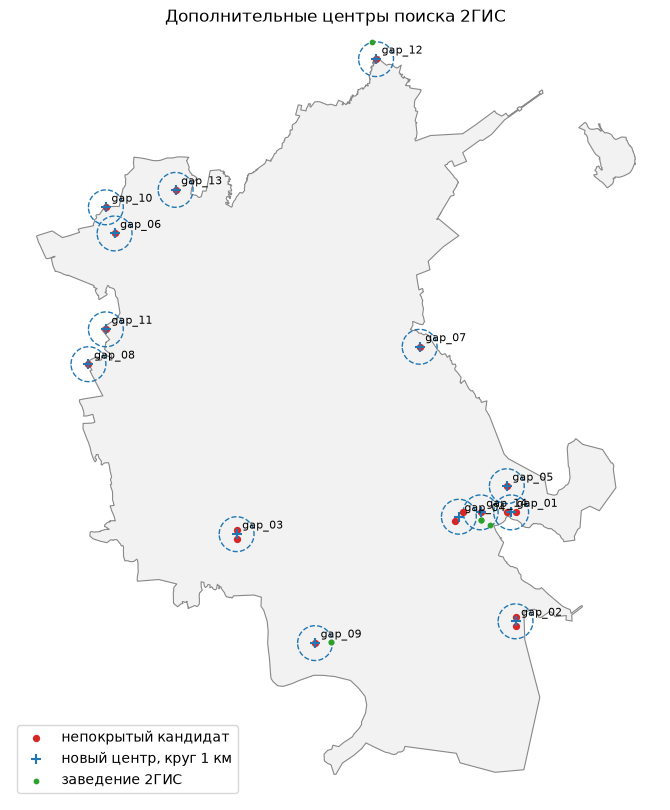

In [9]:
fig, ax = plt.subplots(figsize=(10, 10))
city.plot(ax=ax, color="#f2f2f2", edgecolor="#888888", linewidth=0.8)
centers.buffer(SEARCH_RADIUS_M).boundary.plot(ax=ax, color="#1f77b4", linewidth=1, linestyle="--")
gap.plot(ax=ax, color="#d62728", markersize=18, zorder=3, label="непокрытый кандидат")
centers.plot(ax=ax, color="#1f77b4", marker="+", markersize=60, zorder=3, label="новый центр, круг 1 км")
for _, row in centers.iterrows():
    ax.annotate(row["center_id"], (row["x"], row["y"]), xytext=(4, 4), textcoords="offset points", fontsize=8)
if gap_orgs is not None and len(gap_orgs):
    ax.scatter(gap_orgs["x"], gap_orgs["y"], s=10, color="#2ca02c", zorder=4, label="заведение 2ГИС")
minx, miny, maxx, maxy = city.total_bounds
ax.set_xlim(minx - 1500, maxx + 1500)
ax.set_ylim(miny - 1500, maxy + 1500)
ax.set_title("Дополнительные центры поиска 2ГИС")
ax.legend(loc="lower left")
ax.set_axis_off()
plt.show()